# Circuit diagrams

Stim can draw a circuit in several styles. In a notebook the result shows up inline. Run from `notebooks/tutorials/`.

In [ ]:
import stim
from hackathon_2026 import create_circuit

one_round = create_circuit("X", 1)                          # noiseless, 1 round: easiest to read
full = stim.Circuit.from_file("../../data/X_circuit.stim")  # the competition circuit: 5 rounds + SI1000 noise

## Timeline

One horizontal line per qubit, time running left to right: resets, CNOTs, measurements, and the `DETECTOR` / `OBSERVABLE_INCLUDE` annotations.

In [4]:
import re
svg = str(one_round.diagram("timeline-svg"))
svg = re.sub(r"(<svg[^>]*>)", r'\1<rect width="100%" height="100%" fill="white"/>', svg, count=1)
open("output.svg", "w").write(svg)

118007

The full noisy circuit, with every noise channel drawn. It's long, so scroll sideways.

In [ ]:
full.diagram("timeline-svg")

## Timeslice

The chip layout (qubits at their coordinates), one panel per TICK. Good for seeing which CNOTs run in parallel. `tick=range(a, b)` limits it to a few layers.

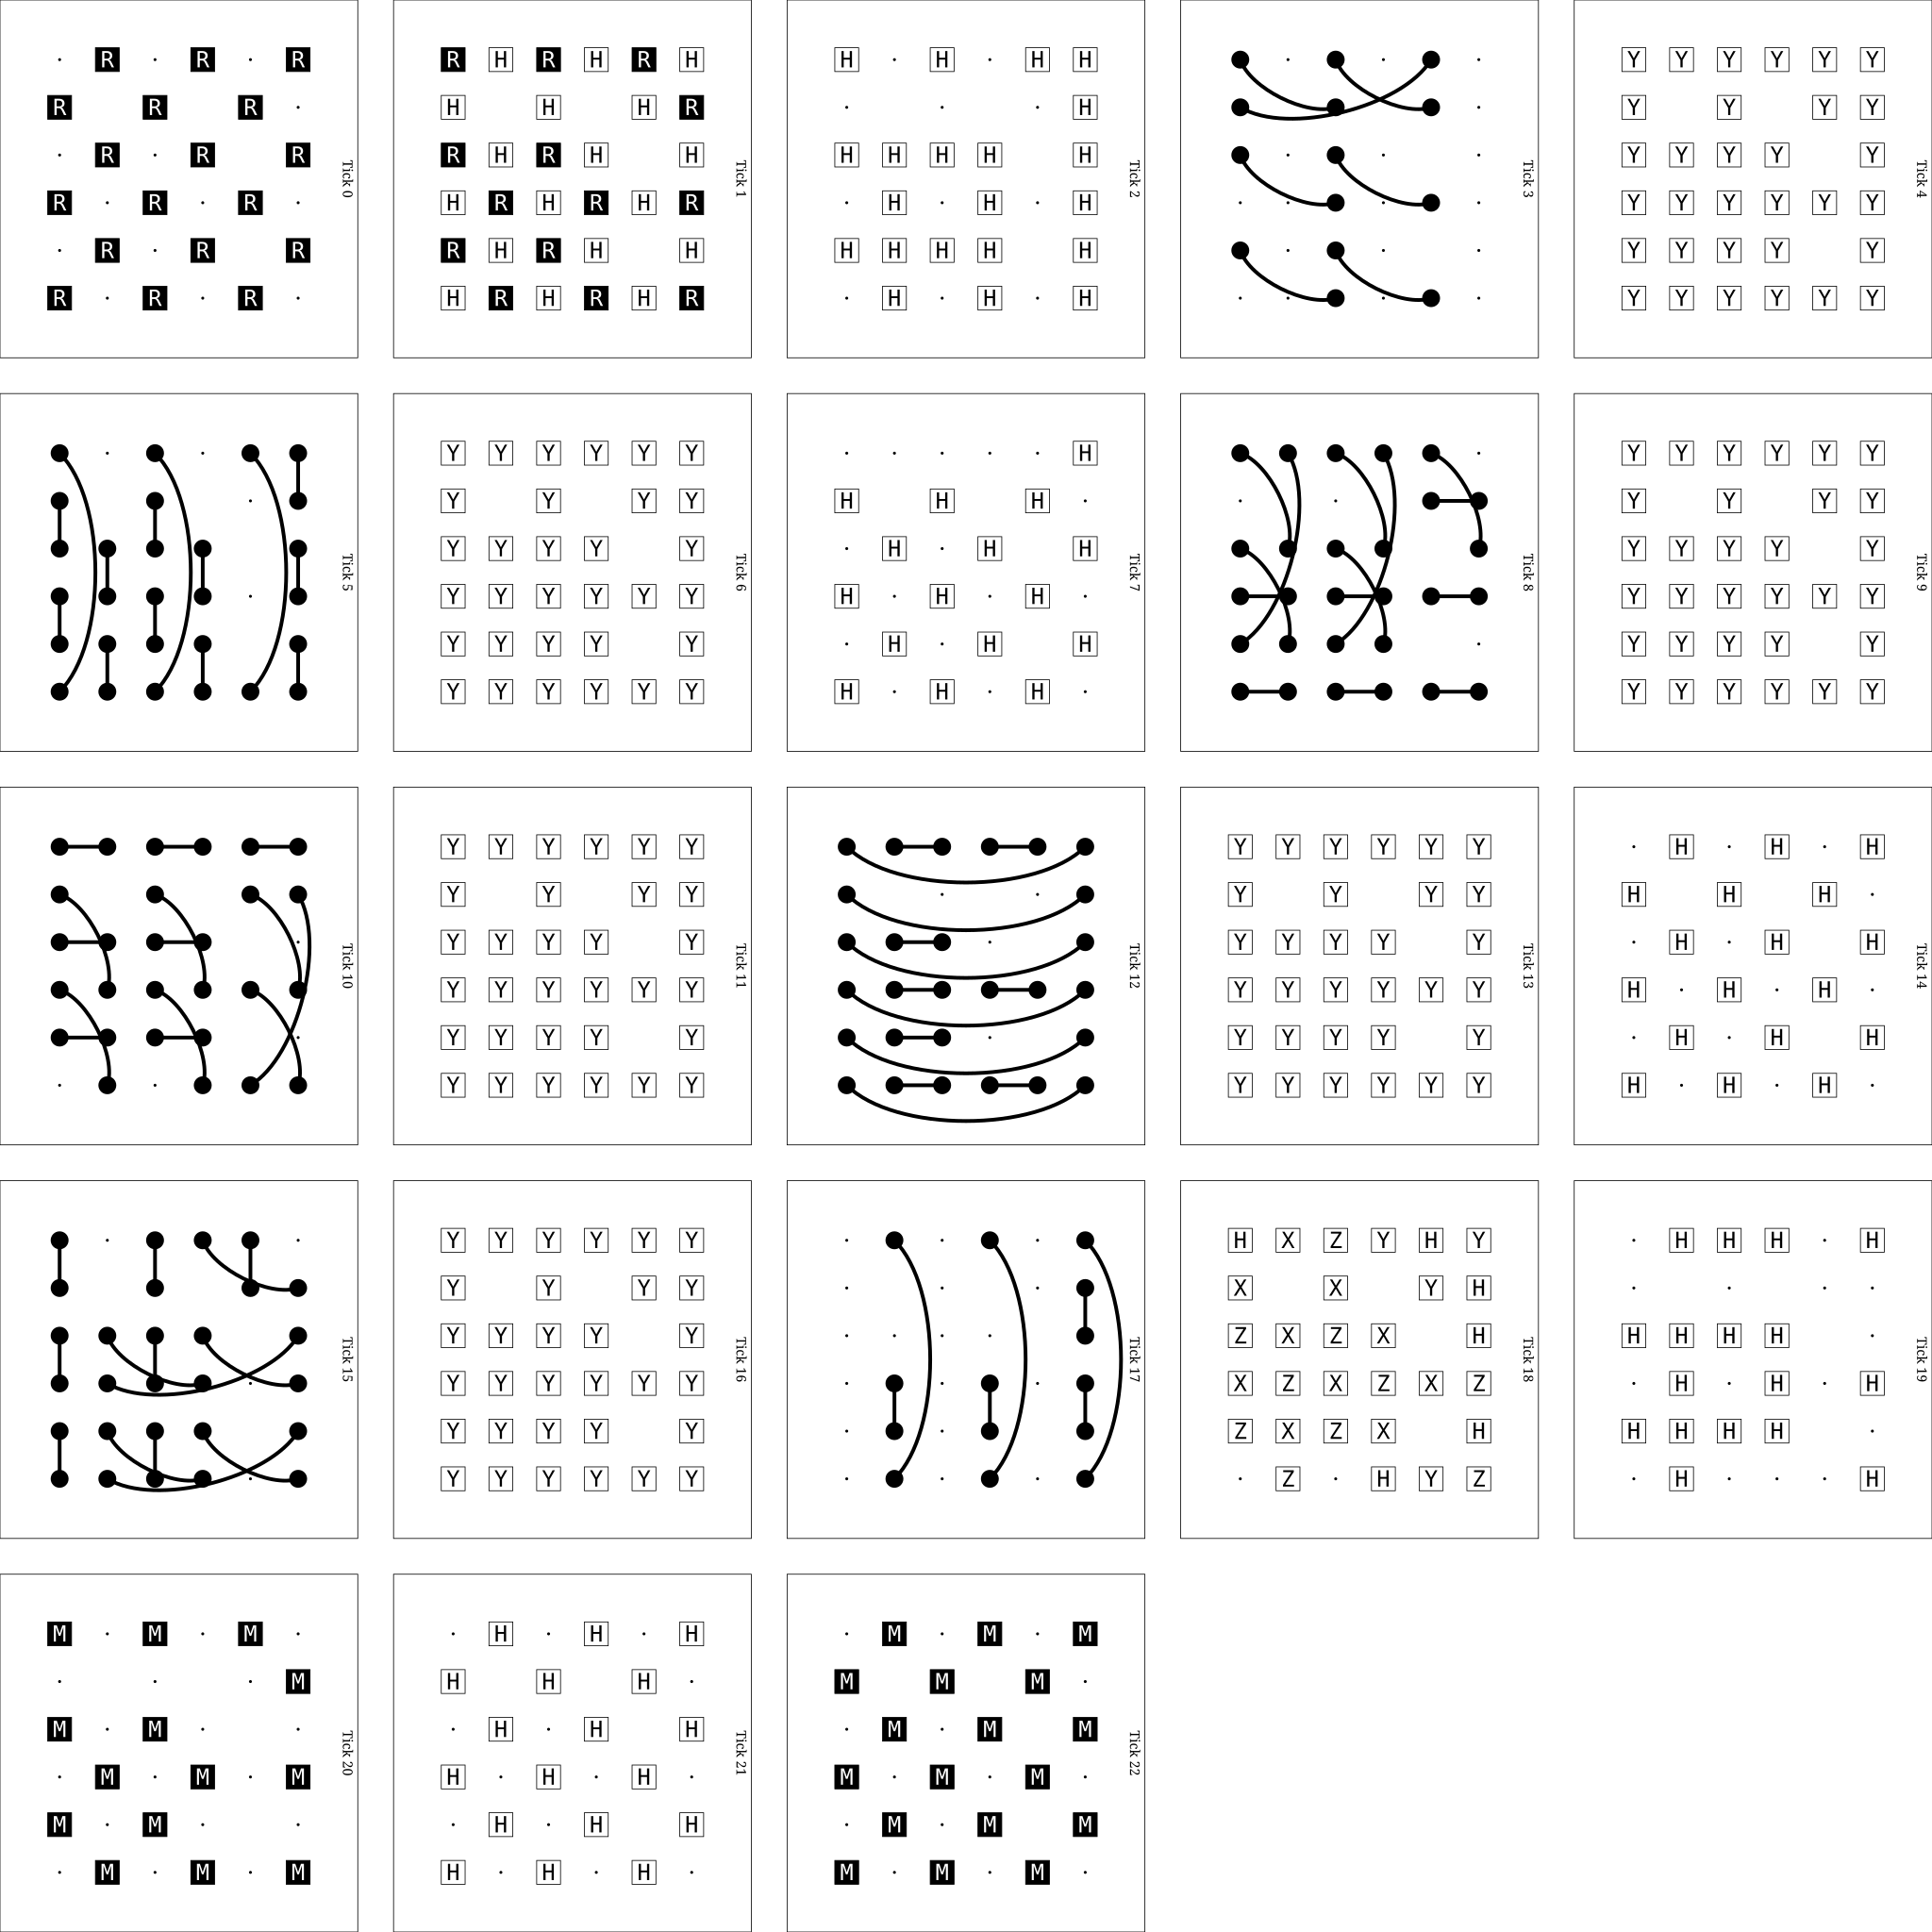

In [5]:
one_round.diagram("timeslice-svg")

## Detector slices

Each panel shows which stabilizer every detector is watching at that moment: this is how D0–D69 map onto the chip.

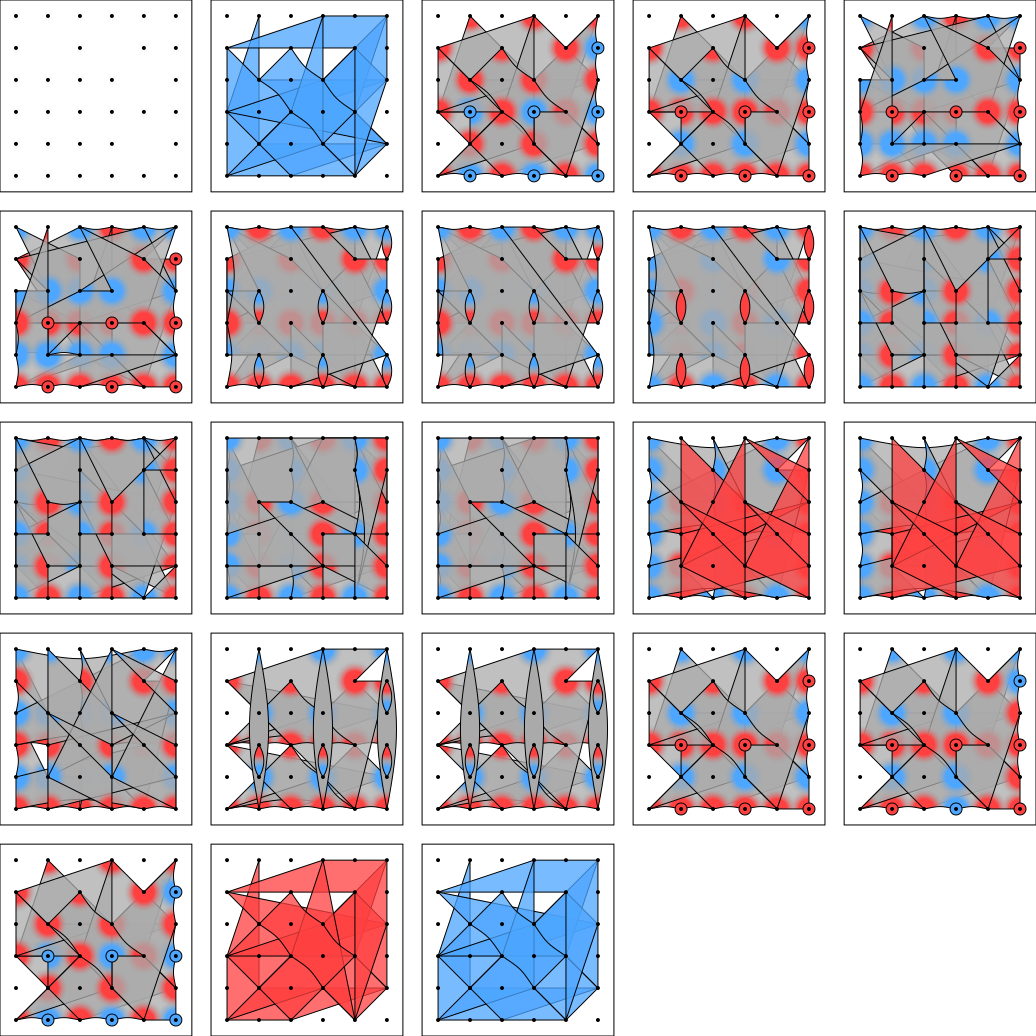

In [6]:
one_round.diagram("detslice-svg")

## Matching graph of the detector error model

Detectors as nodes, error mechanisms as edges (hyperedges are drawn too). This is the picture behind the matrices `H` and `L`.

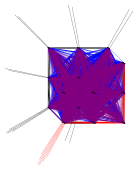

In [7]:
full.diagram("matchgraph-svg")